<a href="https://colab.research.google.com/github/devaramanelohith/ai-agents-cookbook/blob/main/langgraph/Langgraph_states_and_nodes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating a Simple Graph

In [2]:
from typing import TypedDict, List
class State(TypedDict): # Define the structure of the state
    name: str # vinay
    primary_email: str # vinay@gmail.com
    alt_emails: List[str] # vina1@gmail.com, vin2@gmail.com


In [3]:
#Node 1 - Collect
def collect_name_and_primary_email(state:State):
  name = input("Enter your name:")
  email = input("Enter your primary email:")

  return {
      "name": name,
      "primary_email": email
  }

In [4]:
# Node 2: Collect two alternative email address
def collect_alternative_emails(state:State):
  print("\nEnter two alternative email IDs")

  email1 = input("Enter Alternatve Email 1:")
  email2 = input("Enter Alternative Email2:")

  return{
      "alt_emails":[email1,email2]
  }

In [5]:
# Node 3: Display a summary of the collected information
def summary(state: State):
    print("\nRegistration Summary")
    print("Name:", state["name"])
    print("Primary Email:", state["primary_email"])
    print("Alternative Emails:", state["alt_emails"])
    return state

In [6]:
!pip install langgraph langchain

Enter your name:Lohith
Enter your primary email:loh@gmail.com

Enter two alternative email IDs
Enter Alternatve Email 1:loh1@gmail.com
Enter Alternative Email2:loh2@gmail.com

Registration Summary
Name: Lohith
Primary Email: loh@gmail.com
Alternative Emails: ['loh1@gmail.com', 'loh2@gmail.com']


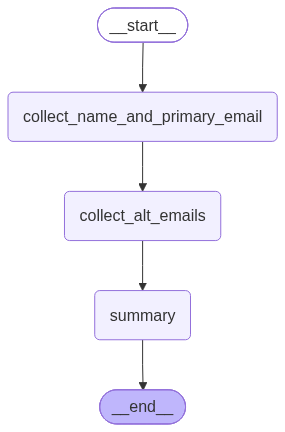

In [7]:
from langgraph.graph import StateGraph, END, START
# Create a graph using the defined State structure
builder = StateGraph(State)
builder.add_node("collect_name_and_primary_email", collect_name_and_primary_email)
builder.add_node("collect_alt_emails",collect_alternative_emails)
builder.add_node("summary",summary)

builder.set_entry_point("collect_name_and_primary_email")

builder.add_edge("collect_name_and_primary_email","collect_alt_emails")
builder.add_edge("collect_alt_emails","summary")

builder.add_edge("summary",END)

graph = builder.compile()

graph.invoke({})
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))